# Lab Task 2



**Task # 01:**

### Lab Task: Affine Transformation Order

Apply **scaling, rotation, and translation** to the given image using a single \(3\times3\) affine transformation matrix. Perform the transformations in the following three different orders:
- **Scaling → Rotation → Translation**
- **Rotation → Scaling → Translation**, and
- **Translation → Rotation → Scaling**.

Display the three resulting images side by side and compare them.

Observe whether changing the order of the transformations changes the final output. Based on your results, explain why the order of matrix multiplication affects the final transformed image.


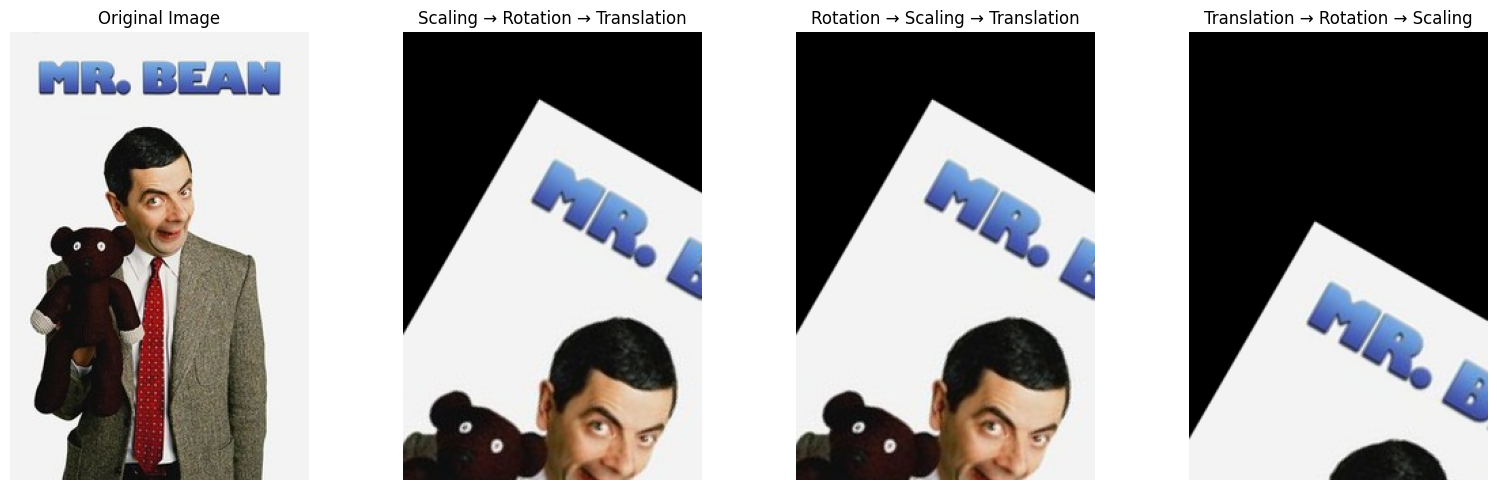

Matrix 1 - Scaling → Rotation → Translation:
[[  1.299038  -0.75     100.      ]
 [  0.75       1.299038  50.      ]
 [  0.         0.         1.      ]]

Matrix 2 - Rotation → Scaling → Translation:
[[  1.299038  -0.75     100.      ]
 [  0.75       1.299038  50.      ]
 [  0.         0.         1.      ]]

Matrix 3 - Translation → Rotation → Scaling:
[[  1.299038  -0.75      92.40381 ]
 [  0.75       1.299038 139.9519  ]
 [  0.         0.         1.      ]]


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt



img = cv2.imread("image.jpg")

# Check if image loaded
if img is None:
    print("Image not found!")
    exit()

# Convert BGR to RGB for matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# Scaling
sx = 1.5
sy = 1.5

# Rotation angle
angle = 30
theta = np.radians(angle)

# Translation
tx = 100
ty = 50



# Scaling Matrix
S = np.array([
    [sx, 0, 0],
    [0, sy, 0],
    [0, 0, 1]
], dtype=np.float32)

# Rotation Matrix
R = np.array([
    [np.cos(theta), -np.sin(theta), 0],
    [np.sin(theta),  np.cos(theta), 0],
    [0, 0, 1]
], dtype=np.float32)

# Translation Matrix
T = np.array([
    [1, 0, tx],
    [0, 1, ty],
    [0, 0, 1]
], dtype=np.float32)


# Scaling → Rotation → Translation
M1 = T @ R @ S

# Rotation → Scaling → Translation
M2 = T @ S @ R

# Translation → Rotation → Scaling
M3 = S @ R @ T

# Apply Transformation


h, w = img.shape[:2]

result1 = cv2.warpAffine(img, M1[:2, :], (w, h))
result2 = cv2.warpAffine(img, M2[:2, :], (w, h))
result3 = cv2.warpAffine(img, M3[:2, :], (w, h))


plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(cv2.cvtColor(result1, cv2.COLOR_BGR2RGB))
plt.title("Scaling → Rotation → Translation")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(cv2.cvtColor(result2, cv2.COLOR_BGR2RGB))
plt.title("Rotation → Scaling → Translation")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(cv2.cvtColor(result3, cv2.COLOR_BGR2RGB))
plt.title("Translation → Rotation → Scaling")
plt.axis("off")

plt.tight_layout()
plt.show()


print("Matrix 1 - Scaling → Rotation → Translation:")
print(M1)

print("\nMatrix 2 - Rotation → Scaling → Translation:")
print(M2)

print("\nMatrix 3 - Translation → Rotation → Scaling:")
print(M3)

**Task # 02:**

Apply image scaling using different interpolation techniques available in OpenCV. Scale the given image up by 2× and compare the results obtained using INTER_NEAREST, INTER_LINEAR, INTER_CUBIC, and INTER_LANCZOS4. Display the original image and all scaled versions together, then compare the images by observing differences in sharpness, smoothness, pixelation, and preservation of fine details. Also print the resulting image dimensions for each interpolation method and briefly state which interpolation method produces the most visually suitable result for upscaling and why.

Original Image Dimensions: 220 x 330
INTER_NEAREST : 440 x 660
INTER_LINEAR  : 440 x 660
INTER_CUBIC   : 440 x 660
INTER_LANCZOS4: 440 x 660


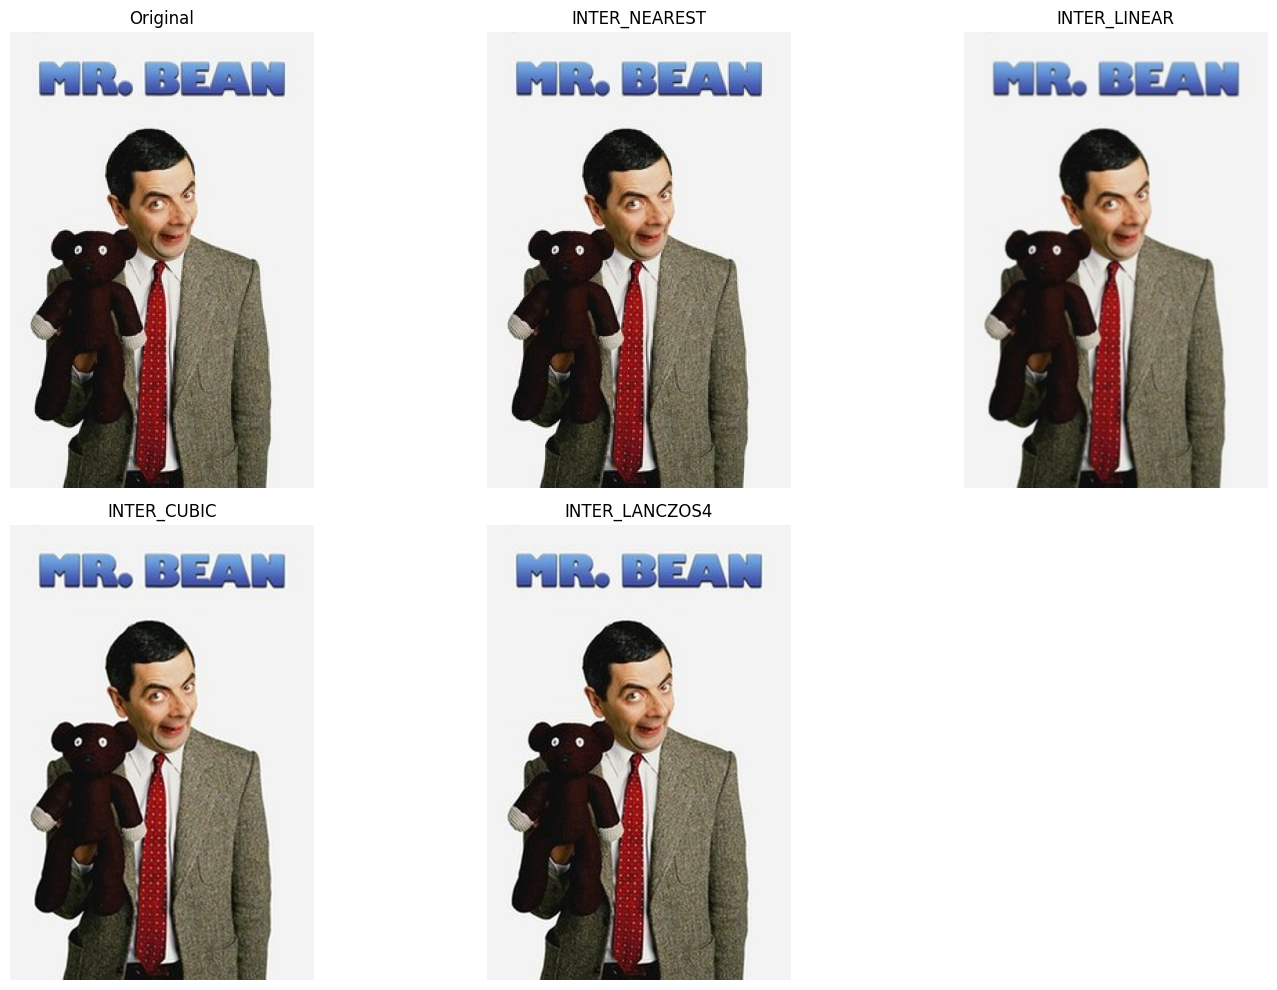

In [2]:
import cv2
import matplotlib.pyplot as plt



img = cv2.imread("image.jpg")

if img is None:
    print("Image not found!")
    exit()

# Convert BGR to RGB for displaying
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)




h, w = img.shape[:2]

print("Original Image Dimensions:", w, "x", h)



nearest = cv2.resize(
    img,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_NEAREST
)

linear = cv2.resize(
    img,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_LINEAR
)

cubic = cv2.resize(
    img,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_CUBIC
)

lanczos = cv2.resize(
    img,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_LANCZOS4
)



print("INTER_NEAREST :", nearest.shape[1], "x", nearest.shape[0])
print("INTER_LINEAR  :", linear.shape[1], "x", linear.shape[0])
print("INTER_CUBIC   :", cubic.shape[1], "x", cubic.shape[0])
print("INTER_LANCZOS4:", lanczos.shape[1], "x", lanczos.shape[0])




plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(img_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(cv2.cvtColor(nearest, cv2.COLOR_BGR2RGB))
plt.title("INTER_NEAREST")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(cv2.cvtColor(linear, cv2.COLOR_BGR2RGB))
plt.title("INTER_LINEAR")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(cv2.cvtColor(cubic, cv2.COLOR_BGR2RGB))
plt.title("INTER_CUBIC")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(cv2.cvtColor(lanczos, cv2.COLOR_BGR2RGB))
plt.title("INTER_LANCZOS4")
plt.axis("off")

plt.tight_layout()
plt.show()

**Task # 03:**

Use any image and apply a homography transformation to change its perspective. Select four points from the image and map them to four new points to create a perspective-distorted or perspective-corrected image. Use cv2.getPerspectiveTransform() to calculate the homography matrix and cv2.warpPerspective() to apply it. Display the original and transformed images and observe how the perspective of the image changes.

Image dimensions: 220 x 330

Homography Matrix:
[[ 1.05613021e-02 -3.03951368e-01  1.00000000e+02]
 [-2.28310502e-01  9.51140335e-03  5.00000000e+01]
 [-6.73024156e-04 -2.55015887e-03  1.00000000e+00]]


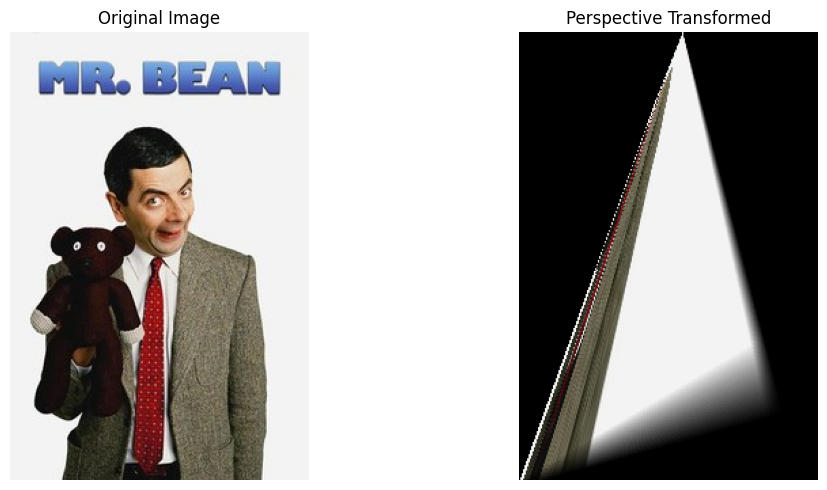

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


img = cv2.imread("image.jpg")

if img is None:
    print("Image not found!")
    exit()



h, w = img.shape[:2]

print("Image dimensions:", w, "x", h)

src_points = np.float32([
    [0, 0],          # Top-left
    [w-1, 0],        # Top-right
    [w-1, h-1],      # Bottom-right
    [0, h-1]         # Bottom-left
])



dst_points = np.float32([
    [100, 50],       # New top-left
    [w-100, 0],      # New top-right
    [w-50, h-100],   # New bottom-right
    [0, h]           # New bottom-left
])



H = cv2.getPerspectiveTransform(
    src_points,
    dst_points
)

print("\nHomography Matrix:")
print(H)


result = cv2.warpPerspective(
    img,
    H,
    (w, h)
)


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Perspective Transformed")
plt.axis("off")

plt.tight_layout()
plt.show()